In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import random
from PIL import Image

In [2]:
for root, dirs, files in os.walk('/kaggle/input'):
    level = root.replace('/kaggle/input', '').count(os.sep)

    if level <= 3:
        print(root)
        print("Folders:", dirs[:10])
        print("Images/files:", len(files))
        print("-" * 40)

/kaggle/input
Folders: ['datasets']
Images/files: 0
----------------------------------------
/kaggle/input/datasets
Folders: ['mosabbirahmed']
Images/files: 0
----------------------------------------
/kaggle/input/datasets/mosabbirahmed
Folders: ['intel-image-classification-no-splits']
Images/files: 0
----------------------------------------
/kaggle/input/datasets/mosabbirahmed/intel-image-classification-no-splits
Folders: ['intel_dataset']
Images/files: 0
----------------------------------------


In [3]:
data_dir='/kaggle/input/datasets/mosabbirahmed/intel-image-classification-no-splits/intel_dataset'

for item in sorted(os.listdir(data_dir)):
    path=os.path.join(data_dir,item)

    if os.path.isdir(path):
        print(f'Folder: {item}')
        print('Number of items:', len(os.listdir(path)))
        print('Sample items:', os.listdir(path)[:5])
        print('-' * 40)
    else:
        print(f'File: {item}')

Folder: buildings
Number of items: 2609
Sample items: ['22735.jpg', '22706.jpg', '2193.jpg', '11378.jpg', '10730.jpg']
----------------------------------------
Folder: forest
Number of items: 2745
Sample items: ['7981.jpg', '3863.jpg', '11925.jpg', '23407.jpg', '10597.jpg']
----------------------------------------
Folder: glacier
Number of items: 2874
Sample items: ['12666.jpg', '13288.jpg', '3750.jpg', '6588.jpg', '7966.jpg']
----------------------------------------
Folder: mountain
Number of items: 3027
Sample items: ['22608.jpg', '14986.jpg', '3138.jpg', '1700.jpg', '16257.jpg']
----------------------------------------
Folder: sea
Number of items: 2762
Sample items: ['19812.jpg', '16916.jpg', '20513.jpg', '10304.jpg', '623.jpg']
----------------------------------------
Folder: street
Number of items: 2883
Sample items: ['20088.jpg', '1269.jpg', '6241.jpg', '14143.jpg', '2008.jpg']
----------------------------------------


In [4]:
#from collections import Counter
classes=sorted([
    name for name in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir,name))
])
print('calsses: ',classes)

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

counts = {}

for class_name in classes:
    class_path=os.path.join(data_dir,class_name)

    images=[
      f for f in os.listdir(class_path)
      if f.lower().endswith(image_extensions)
    and os.path.isfile(os.path.join(class_path,f))
  ]
    counts[class_name]=len(images)

print("\nNumber of images per class:")
for name, count in counts.items():
    print(f"{name}: {count}")

print("\nTotal images:", sum(counts.values()))



calsses:  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Number of images per class:
buildings: 2609
forest: 2745
glacier: 2874
mountain: 3027
sea: 2762
street: 2883

Total images: 16900


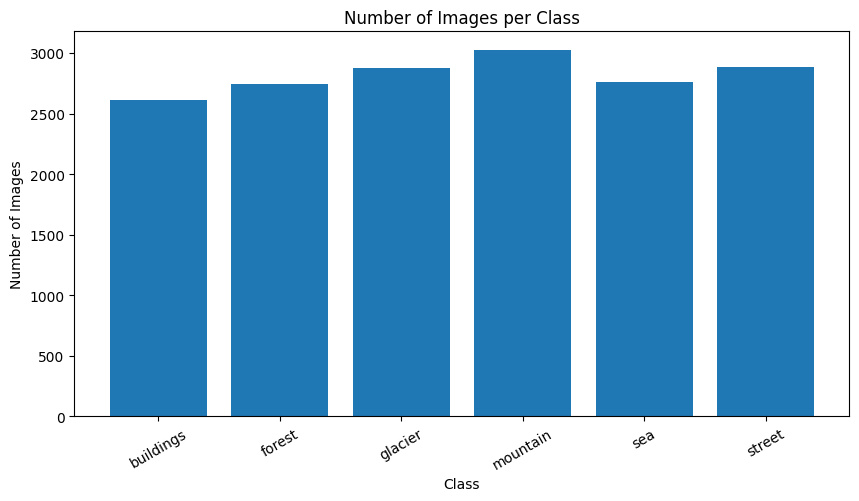

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(counts.keys(), counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()

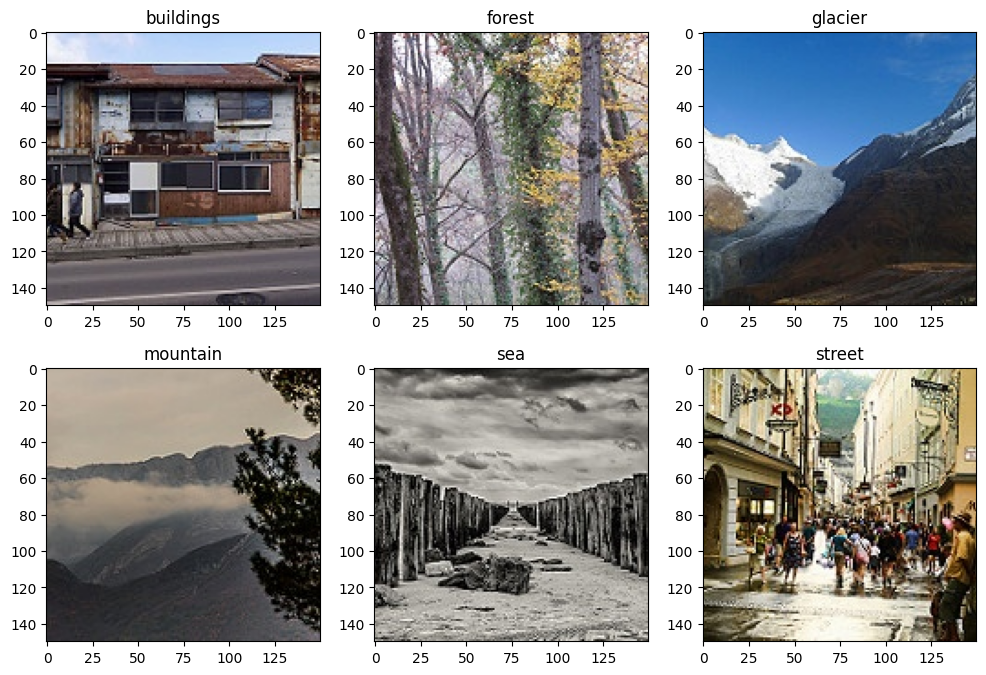

In [6]:
plt.figure(figsize=(12,8))

for i,class_name in enumerate(classes[:6]):
    class_path=os.path.join(data_dir,class_name)

    images=[
        f for f in os.listdir(class_path)
        if f.lower().endswith(image_extensions)
        and os.path.isfile(os.path.join(class_path,f))
    ]

    if not images:
        continue

    image_name=random.choice(images)
    image_path=os.path.join(class_path,image_name)

    img=Image.open(image_path).convert("RGB")

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(class_name)

In [7]:
filepaths=[]
labels=[]

for class_name in classes:
    class_path=os.path.join(data_dir,class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            filepaths.append(os.path.join(class_path,file))
            labels.append(class_name)

df=pd.DataFrame({
    'filepath':filepaths,
    'label':labels
})

train_df,temp_df=train_test_split(df,test_size=.20,random_state=42,stratify=df['label'])

val_df,test_df=train_test_split(temp_df,test_size=.50,random_state=42,stratify=temp_df['label'])

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTrain class distribution:")
print(train_df['label'].value_counts().sort_index())


Train images: 13520
Validation images: 1690
Test images: 1690

Train class distribution:
label
buildings    2087
forest       2196
glacier      2299
mountain     2422
sea          2210
street       2306
Name: count, dtype: int64


In [8]:
img_size=(150,150)
batch_size=32

train_datagen=ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

eval_datagen=ImageDataGenerator(rescale=1./255)

train_gen=train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True,
    seed=42
    
)

val_gen=eval_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)
test_gen = eval_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


print("Class indices:", train_gen.class_indices)

Found 13520 validated image filenames belonging to 6 classes.
Found 1690 validated image filenames belonging to 6 classes.
Found 1690 validated image filenames belonging to 6 classes.
Class indices: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [9]:
model=models.Sequential([
    layers.Input(shape=(150,150,3)),

    layers.Conv2D(32,(3,3),padding='same',activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),padding='same',activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128,(3,3),padding='same',activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(len(classes),activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy'
    ,metrics=['accuracy']
)

model.summary()

I0000 00:00:1793422976.273928      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793422976.281094      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,566 (20.61 MB)

 Trainable params: 5,402,566 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history=model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


2026-10-31 05:03:03.436200: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 05:03:03.584917: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  1/423 ━━━━━━━━━━━━━━━━━━━━ 50:17 7s/step - accuracy: 0.1562 - loss: 1.7858

I0000 00:00:1793422985.993807      72 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


106/423 ━━━━━━━━━━━━━━━━━━━━ 2:05 395ms/step - accuracy: 0.3855 - loss: 1.4938

2026-10-31 05:03:48.756856: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 05:03:48.902160: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


423/423 ━━━━━━━━━━━━━━━━━━━━ 189s 430ms/step - accuracy: 0.5829 - loss: 1.0596 - val_accuracy: 0.7213 - val_loss: 0.7529 - learning_rate: 0.0010
Epoch 2/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 85s 201ms/step - accuracy: 0.6974 - loss: 0.8064 - val_accuracy: 0.7817 - val_loss: 0.6319 - learning_rate: 0.0010
Epoch 3/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 85s 202ms/step - accuracy: 0.7494 - loss: 0.6834 - val_accuracy: 0.8278 - val_loss: 0.4866 - learning_rate: 0.0010
Epoch 4/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 85s 202ms/step - accuracy: 0.7772 - loss: 0.6185 - val_accuracy: 0.8231 - val_loss: 0.5052 - learning_rate: 0.0010
Epoch 5/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.7940 - loss: 0.5600
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
423/423 ━━━━━━━━━━━━━━━━━━━━ 87s 206ms/step - accuracy: 0.8014 - loss: 0.5478 - val_accuracy: 0.8320 - val_loss: 0.5081 - learning_rate: 0.0010
Epoch 6/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 89s 211ms/step - accuracy: 0.8374 - loss:

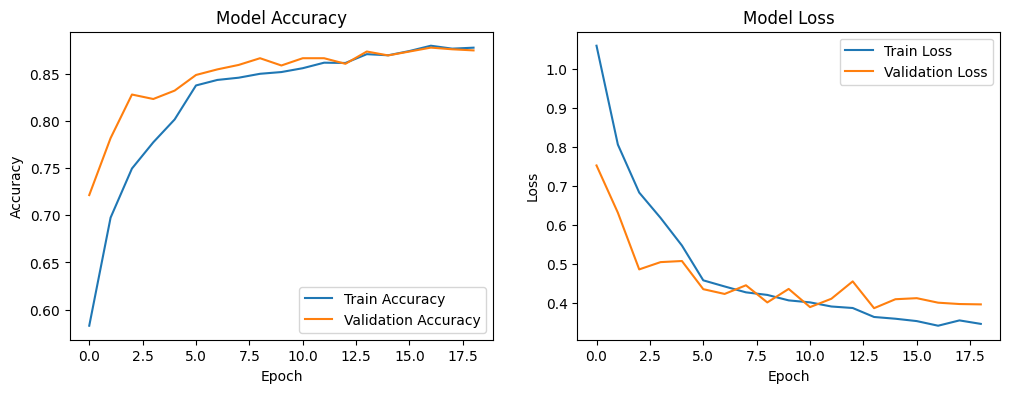

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()